# Visualización con Matplotlib — Apuntes y Notebook práctico
**Asignatura:** Sistemas de Aprendizaje Automático  
**Curso:** Material didáctico para clase práctico (Google Colab / Jupyter)  



---
## Índice (rápido)
1. Introducción a la visualización y librerías (breve)
2. Primeros pasos con `matplotlib.pyplot`
3. Tipos de gráficos: líneas, barras, histograma, scatter, pie
4. Subplots: `subplots()` (forma recomendada) y `subplot()` (forma clásica)
5. Compartir ejes (`sharex`, `sharey`) y `tight_layout`
6. Anotaciones, leyendas, estilos y personalización
7. Buenas prácticas y errores frecuentes
8. Ejercicios propuestos y soluciones
---


In [24]:
# Imports básicos (listos para ejecutar en Colab)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# En Colab es común usar esto para que los gráficos se muestren en la salida
%matplotlib inline

print('numpy:', np.__version__, 'pandas:', pd.__version__)

numpy: 2.5.4 pandas: 3.1.1


## 2) Primeros pasos: `plot()` (diagrama de líneas)
El flujo general para trazar con Matplotlib:
1. importar `pyplot` (`import matplotlib.pyplot as plt`)
2. preparar datos (`list`, `numpy` arrays, `pandas.Series`...)
3. llamar a funciones de dibujo (`plot`, `bar`, `hist`, ...)
4. personalizar (título, etiquetas, leyenda, grid)
5. mostrar (`plt.show()` — en notebooks no es necesario pero es buena práctica)

Ejemplo simple:

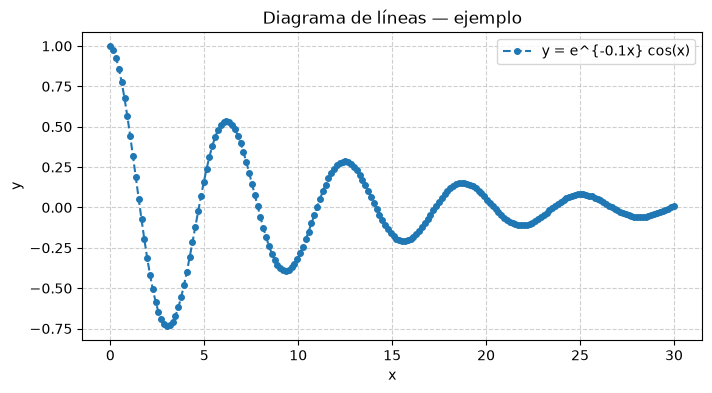

In [25]:
# Genera 200 puntos equiespaciados entre 0 y 30 y los guarda en el array x
x = np.linspace(0, 30, 200)

# Calcula para cada x la función y = e^(-0.1x) * cos(x)
# np.exp() → función exponencial, np.cos() → coseno
y = np.exp(-0.1 * x) * np.cos(x)

# Crea una nueva figura para el gráfico, definiendo su tamaño en pulgadas (8 de ancho, 4 de alto)
plt.figure(figsize=(8, 4))

# Dibuja una curva de línea con:
#   x e y → datos
#   linestyle='--' → línea discontinua
#   marker='o'     → marcador circular en cada punto
#   markersize=4   → tamaño de los marcadores
#   label=...      → etiqueta para la leyenda
plt.plot(x, y, linestyle='--', marker='o', markersize=4, label='y = e^{-0.1x} cos(x)')

# Etiqueta para el eje X
plt.xlabel('x')

# Etiqueta para el eje Y
plt.ylabel('y')

# Título en la parte superior de la figura
plt.title('Diagrama de líneas — ejemplo')

# Muestra la leyenda (usa el texto definido en label)
plt.legend()

# Activa la cuadrícula (grid) con línea discontinua (‘--’) y transparencia (alpha=0.6)
plt.grid(ls='--', alpha=0.6)

# Muestra el gráfico en pantalla
plt.show()

### Varias curvas en la misma figura
Mostrar más de una curva y añadir leyenda:

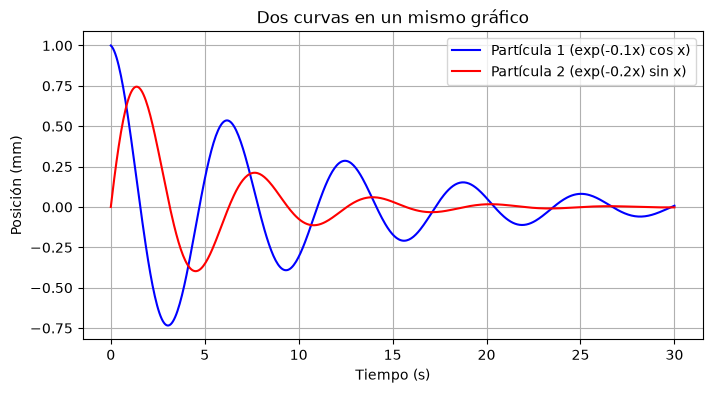

In [26]:
# Dos curvas con leyenda
x = np.linspace(0, 30, 500)
y1 = np.exp(-0.1*x)*np.cos(x)
y2 = np.exp(-0.2*x)*np.sin(x)

plt.figure(figsize=(8,4))
plt.plot(x, y1, 'b-', label='Partícula 1 (exp(-0.1x) cos x)')
plt.plot(x, y2, 'r-', label='Partícula 2 (exp(-0.2x) sin x)')
plt.xlabel('Tiempo (s)')
plt.ylabel('Posición (mm)')
plt.title('Dos curvas en un mismo gráfico')
plt.legend()
plt.grid()
plt.show()

## 4) `subplots()` — la forma recomendada de crear múltiples ejes
La función `plt.subplots()` crea una `Figure` y uno o varios `Axes`. Es la forma recomendada cuando quieres una rejilla de ejes (p. ej. 2x2).
`fig, ax = plt.subplots(nrows, ncols, figsize=(w,h))` devuelve:
- `fig`: la figura
- `ax`: un array (o un único Axes) con las referencias a cada eje

A continuación ejemplos prácticos, incluyendo `sharex` y `sharey` .

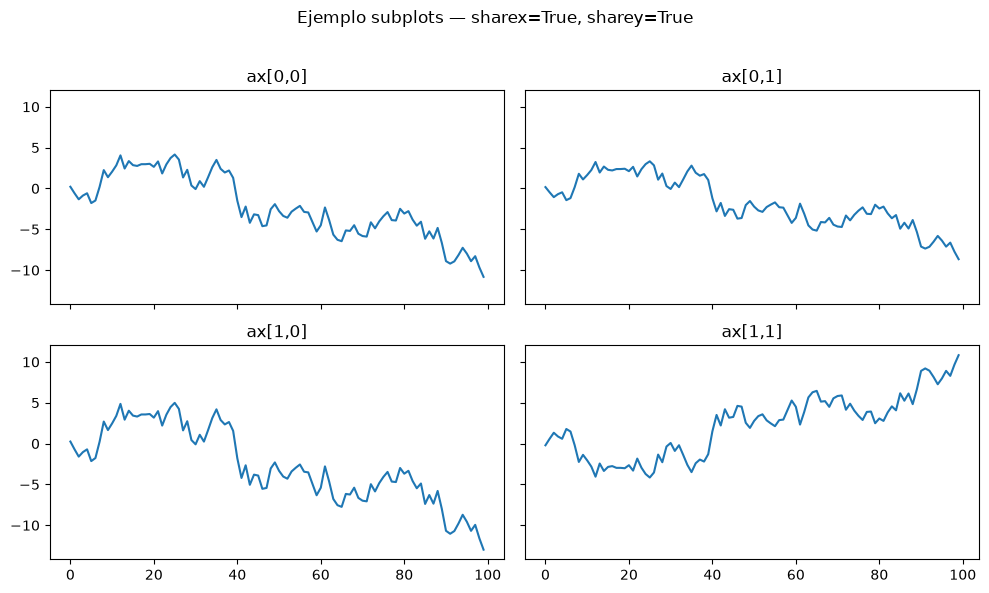

In [27]:
# Ejemplo: matriz 2x2 con sharex/sharey
y = np.random.randn(100).cumsum()

fig, ax = plt.subplots(2, 2, sharex=True, sharey=True, figsize=(10,6))
fig.suptitle('Ejemplo subplots — sharex=True, sharey=True')

ax[0,0].plot(y)
ax[0,0].set_title('ax[0,0]')
ax[0,1].plot(y*0.8)
ax[0,1].set_title('ax[0,1]')
ax[1,0].plot(y*1.2)
ax[1,0].set_title('ax[1,0]')
ax[1,1].plot(-y)
ax[1,1].set_title('ax[1,1]')

plt.tight_layout(rect=[0, 0, 1, 0.96])  # deja espacio para suptitle
plt.show()

### `subplot()` — la forma clásica (útil para crear ejes uno a uno)
`plt.subplot(m, n, k)` crea un solo *axes* en la posición `k` de una cuadrícula `m x n`. Se muestra claramente la numeración y el uso de `subplot` para 2 gráficos apilados.

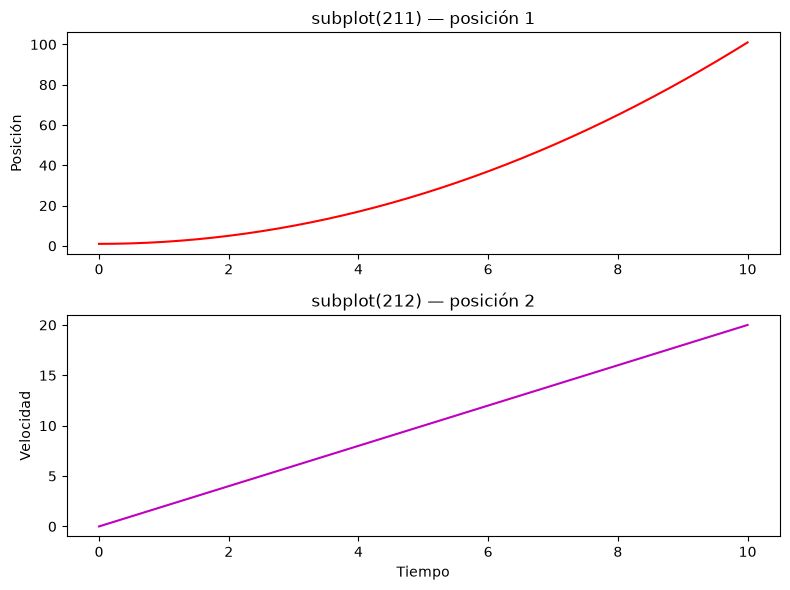

In [28]:
# Ejemplo con subplot() — 2 filas, 1 columna (211 y 212)
t = np.linspace(0,10,200)
s1 = t**2 + 1
s2 = 2*t

plt.figure(figsize=(8,6))
plt.subplot(211)   # 2 filas, 1 columna, posición 1
plt.plot(t, s1, 'r')
plt.ylabel('Posición')
plt.title('subplot(211) — posición 1')

plt.subplot(212)   # posición 2
plt.plot(t, s2, 'm')
plt.ylabel('Velocidad')
plt.xlabel('Tiempo')
plt.title('subplot(212) — posición 2')

plt.tight_layout()
plt.show()

## 3) Tipos de gráficas habituales (resumen + ejemplos)
- Barras (`bar`)
- Histograma (`hist`)
- Dispersión (`scatter`)
- Pie/sector (`pie`)


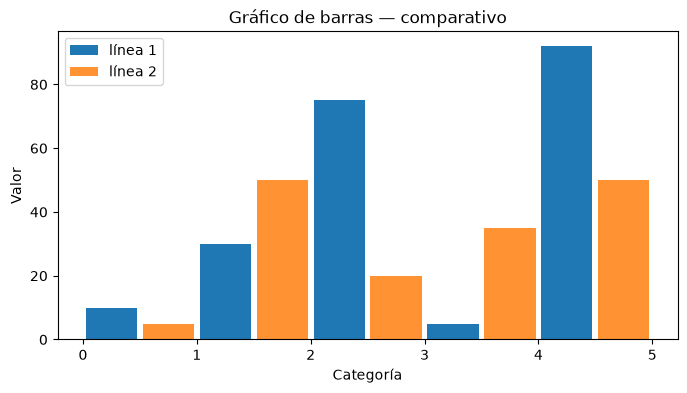

In [29]:
# Gráfico de barras comparativo
x1 = [0.25,1.25,2.25,3.25,4.25]
x2 = [0.75,1.75,2.75,3.75,4.75]
y1 = [10,30,75,5,92]
y2 = [5,50,20,35,50]

plt.figure(figsize=(8,4))
plt.bar(x1, y1, label='línea 1', width=0.45)
plt.bar(x2, y2, label='línea 2', width=0.45, alpha=0.85)
plt.title('Gráfico de barras — comparativo')
plt.xlabel('Categoría')
plt.ylabel('Valor')
plt.legend()
plt.show()

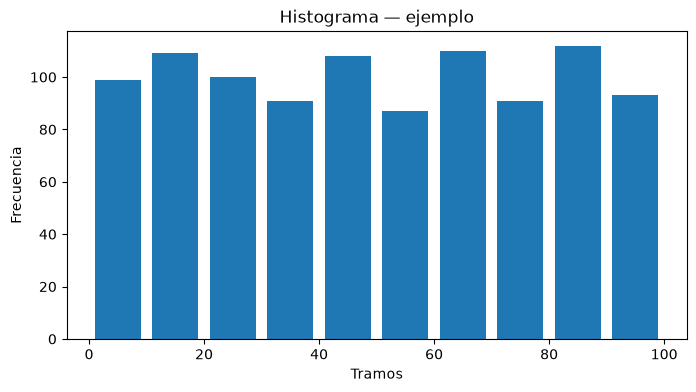

In [30]:
# Histograma
data = np.random.randint(0,100, size=1000)
sections = np.linspace(0,100,11)

plt.figure(figsize=(8,4))
plt.hist(data, sections, histtype='bar', rwidth=0.8)
plt.title('Histograma — ejemplo')
plt.xlabel('Tramos')
plt.ylabel('Frecuencia')
plt.show()

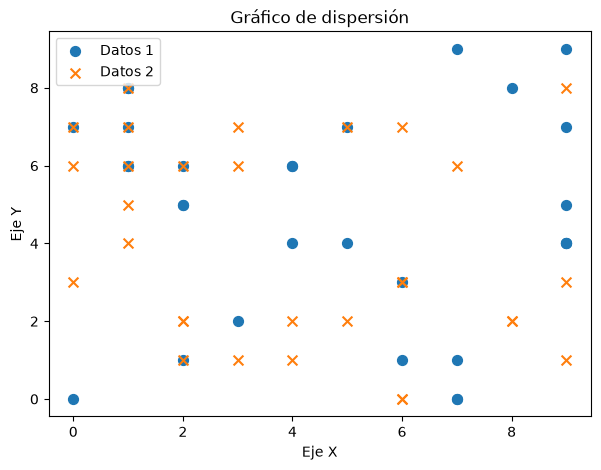

In [31]:
# Scatter (dispersión)
x1 = np.random.randint(0,10, size=30)
y1 = np.random.randint(0,10, size=30)
x2 = np.random.randint(0,10, size=30)
y2 = np.random.randint(0,10, size=30)

plt.figure(figsize=(7,5))
plt.scatter(x1, y1, label='Datos 1', s=50)
plt.scatter(x2, y2, label='Datos 2', s=50, marker='x')
plt.title('Gráfico de dispersión')
plt.xlabel('Eje X')
plt.ylabel('Eje Y')
plt.legend()
plt.show()

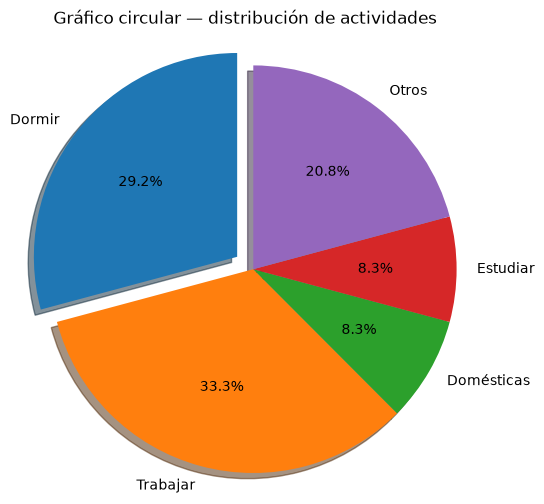

In [32]:
# Pie / gráfico circular
datos = [7,8,2,2,5]
actividades = ['Dormir','Trabajar','Domésticas','Estudiar','Otros']

plt.figure(figsize=(6,6))
plt.pie(datos, labels=actividades, autopct='%1.1f%%', startangle=90, explode=(0.1,0,0,0,0), shadow=True)
plt.title('Gráfico circular — distribución de actividades')
plt.axis('equal')  # para que el círculo quede proporcionado
plt.show()

## 6) Anotaciones y texto dentro del gráfico
Puedes usar `plt.text(x,y,'texto')` para colocar anotaciones, y controlar `fontsize`, `color`, `fontname`, etc.

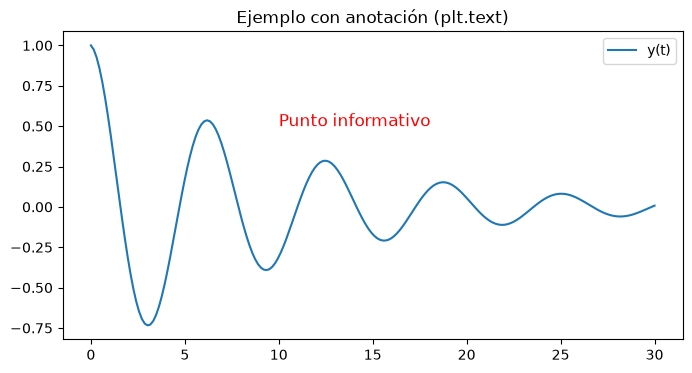

In [33]:
# Ejemplo de anotación
x = np.linspace(0,30,200)
y = np.exp(-0.1*x)*np.cos(x)

plt.figure(figsize=(8,4))
plt.plot(x,y, label='y(t)')
plt.text(10, 0.5, 'Punto informativo', fontsize=12, color='red')
plt.title('Ejemplo con anotación (plt.text)')
plt.legend()
plt.show()

## 8) Ejercicios propuestos (para realizar en clase)
1. Reproducir el diagrama de barras pero cargando datos desde un `pandas.DataFrame`.  
2. Representar la función \(y = \cos(x) e^{-0.1x}\) en \([0,30]\) con 5, 50 y 1000 puntos — comentar las diferencias.  
3. Crear una figura con `subplots(3,2)` y en cada subgráfico mostrar una distribución distinta (normal, uniforme, poisson, binomial, exponencial, gamma).  
4. (Desafío) Dado un dataset real (puedes usar `seaborn.load_dataset('tips')`), identificar un gráfico útil para responder una pregunta — justificar y mostrarlo.

Debajo encontrarás soluciones orientadas (código listo para ejecutar).

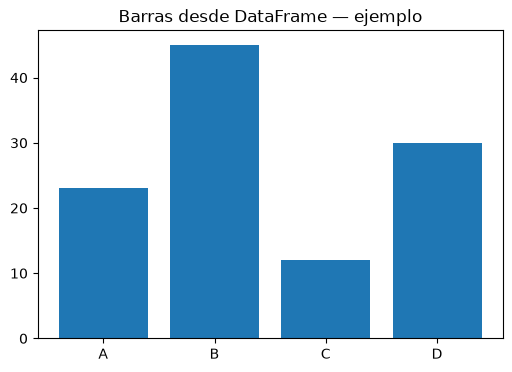

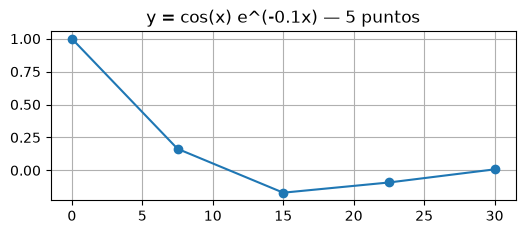

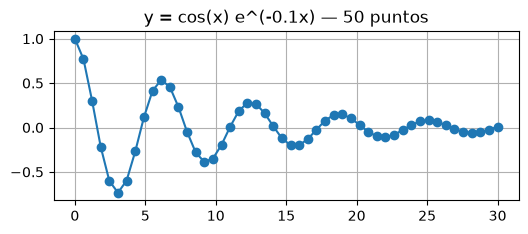

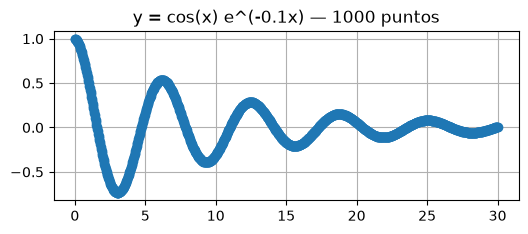

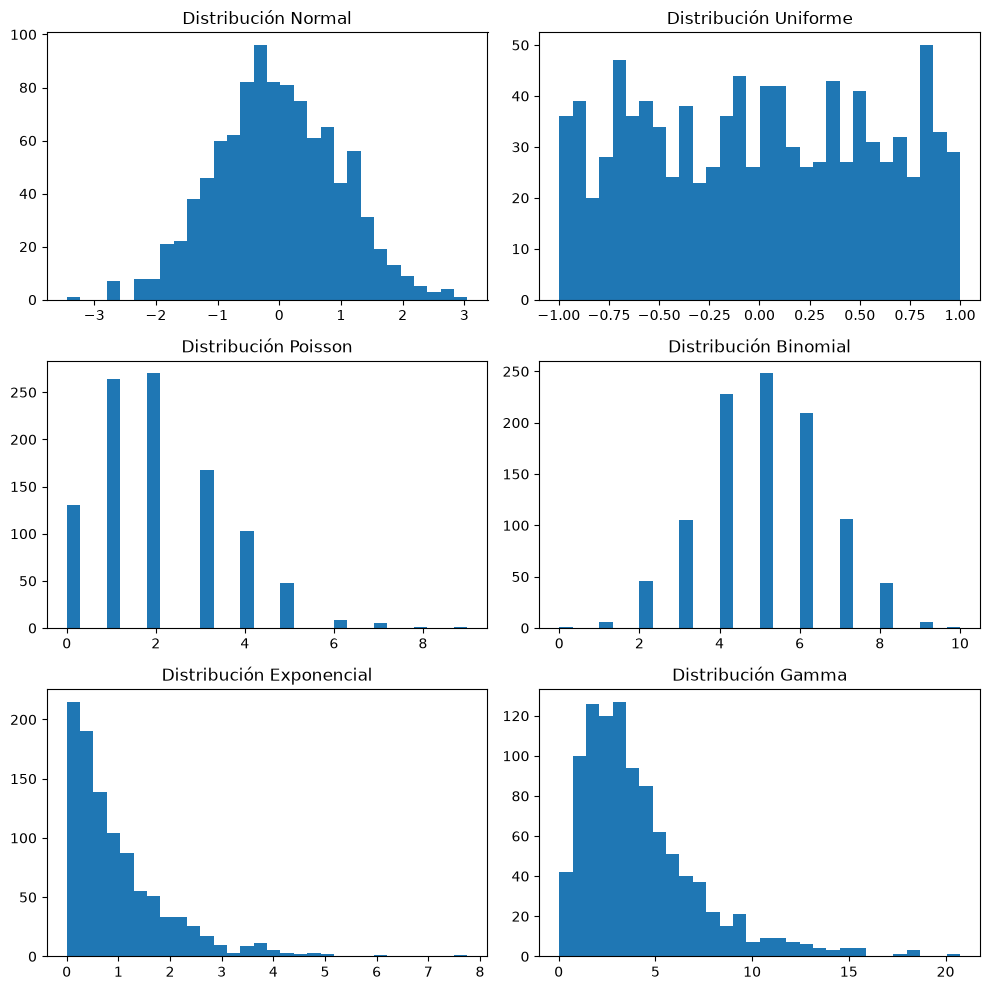

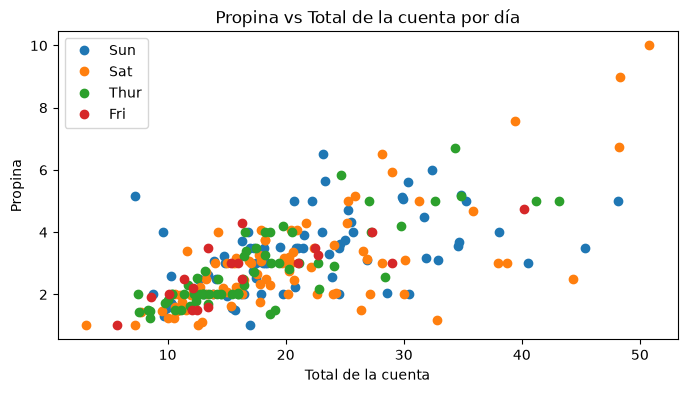

In [ ]:
# Soluciones orientadas (ejercicio 1 y 2 como ejemplo)

# Ejercicio 1: barras desde DataFrame
df = pd.DataFrame({
    'categoria': ['A','B','C','D'],
    'valores': [23, 45, 12, 30]
})
plt.figure(figsize=(6,4))
plt.bar(df['categoria'], df['valores'])
plt.title('Barras desde DataFrame — ejemplo')
plt.show()

# Ejercicio 2: misma función con distinto número de puntos
import math
f = lambda x: math.cos(x) * math.exp(-0.1*x)

for n in [5, 50, 1000]:
    x = np.linspace(0,30,n)
    y = [f(xx) for xx in x]
    plt.figure(figsize=(6,2.2))
    plt.plot(x,y, marker='o')
    plt.title(f'y = cos(x) e^(-0.1x) — {n} puntos')
    plt.grid()
    plt.show()
    
# Ejercicio 3: subplots con distribuciones
fig, axes = plt.subplots(3, 2, figsize=(10, 10))
axes = axes.flatten()

# Distribución normal
axes[0].hist(np.random.normal(0, 1, 1000), bins=30)
axes[0].set_title('Distribución Normal')

# Distribución uniforme
axes[1].hist(np.random.uniform(-1, 1, 1000), bins=30)
axes[1].set_title('Distribución Uniforme')

# Distribución Poisson
axes[2].hist(np.random.poisson(2, 1000), bins=30)
axes[2].set_title('Distribución Poisson')

# Distribución binomial
axes[3].hist(np.random.binomial(10, 0.5, 1000), bins=30)
axes[3].set_title('Distribución Binomial')

# Distribución exponencial
axes[4].hist(np.random.exponential(1, 1000), bins=30)
axes[4].set_title('Distribución Exponencial')

# Distribución gamma
axes[5].hist(np.random.gamma(2, 2, 1000), bins=30)
axes[5].set_title('Distribución Gamma')

plt.tight_layout()
plt.show()

# Ejercicio 4: Dado un dataset real (puedes usar `seaborn.load_dataset('tips')`), identificar un gráfico útil para responder una pregunta — justificar y mostrarlo.
df_tips = sns.load_dataset('tips')
plt.figure(figsize=(8,4))
# explorando los días únicos en la columna 'day' del DataFrame df_tips
for day in df_tips['day'].unique():
    # seleccionar el subconjunto de datos para el día actual
    subset = df_tips[df_tips['day'] == day]
    plt.plot(subset['total_bill'], subset['tip'], marker='o', linestyle='', label=day)
plt.title('Propina vs Total de la cuenta por día')
# plt.xlabel('Total de la cuenta')
plt.ylabel('Propina')
plt.legend()
plt.show()

Podemos ver una relación entre mas cara es la cuenta, mas propina se le deja 

## 7) Buenas prácticas y errores frecuentes (resumen)
- Elegir el tipo de gráfico que mejor represente la pregunta (barras para comparaciones categóricas, hist para distribuciones, scatter para relaciones).
- Evaluar el número de puntos al graficar funciones: pocos puntos ocultan la forma; demasiados pueden ser costosos en rendimiento.
- Usar `subplots()` cuando necesites una rejilla de ejes; `subplot()` para un control rápido y puntual.
- Ajustar `tight_layout()` para evitar solapamientos de etiquetas y títulos.  
- Añadir leyendas y etiquetas claras: la buena visualización comunica sin ambigüedad.
